In [1]:
import anomaly_detection as ad
import pandas as pd
import os
import sys
import matplotlib.pyplot as plt

from analysis import *

In [2]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [7]:
%%capture root_dir
!git rev-parse --show-toplevel
# Get the root directory for the github repo

In [8]:
root_dir = "".join(root_dir.stdout.split())

In [10]:
experiment1 = 'no_filter'
data_file1 = f'../experiments/{experiment1}/final_data.csv'
data1 = pd.read_csv(data_file1)
metrics1 = ad.get_anomaly_metrics(experiment1, f'gestalt_output/mp0.8_tq10', root_dir)

experiment2 = 'used_filter'
data_file2 = f'../experiments/{experiment2}/final_data.csv'
data2 = pd.read_csv(data_file2)
metrics2 = ad.get_anomaly_metrics(experiment2, f'gestalt_output/mp0.8_tq10', root_dir)

experiment3 = 'full_pipeline'
data_file3 = f'../experiments/{experiment3}/final_data.csv'
data3 = pd.read_csv(data_file3)

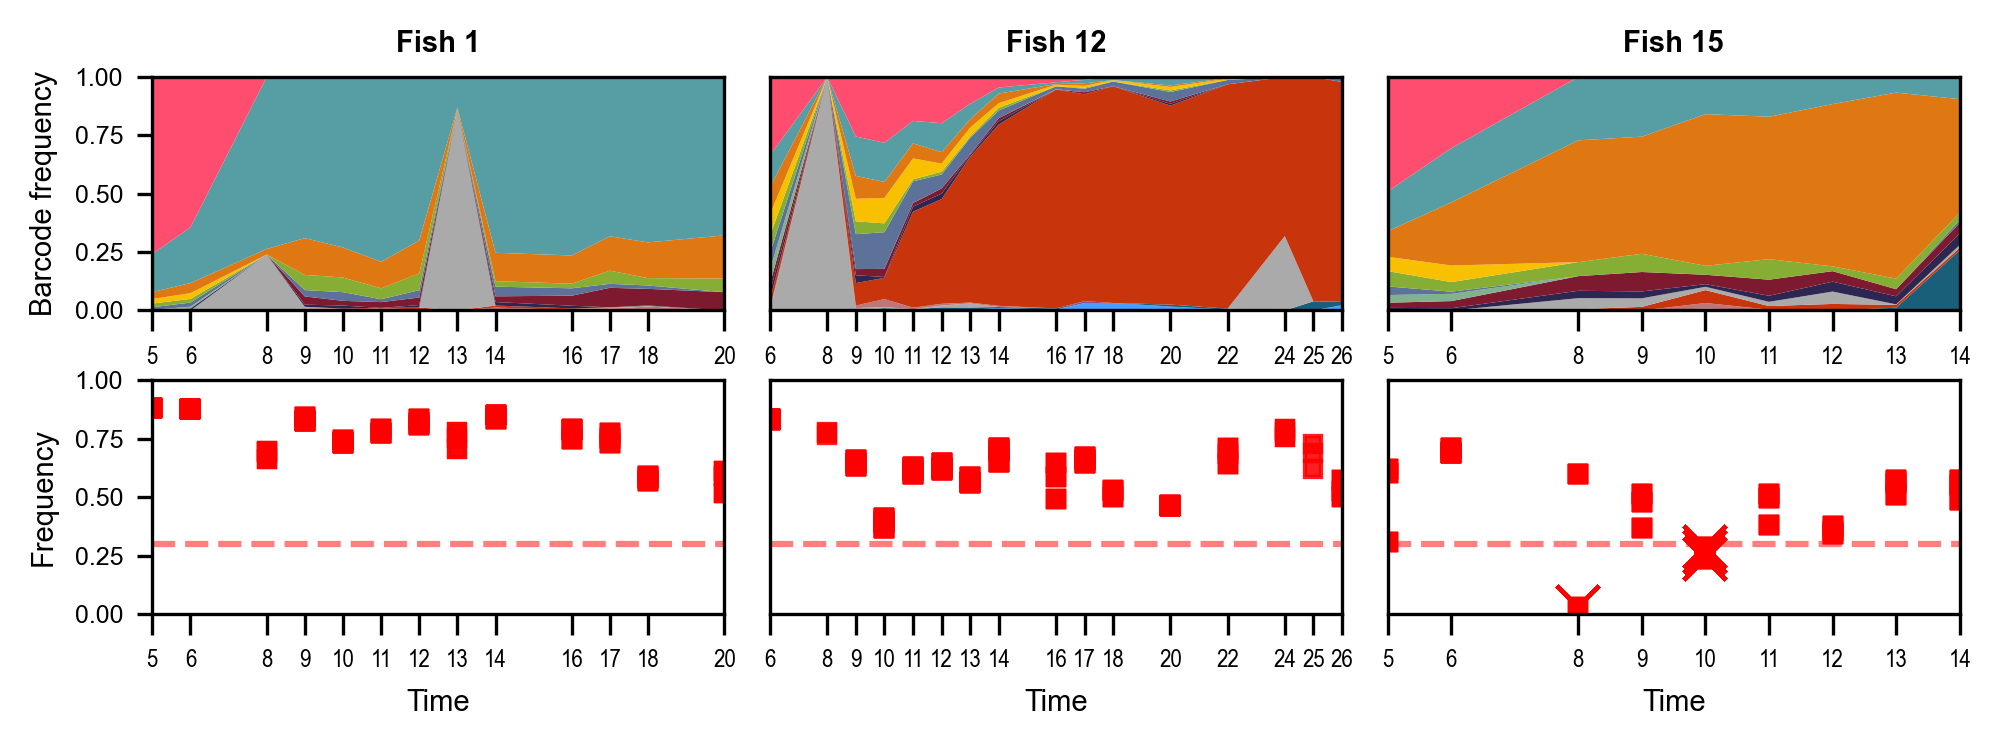

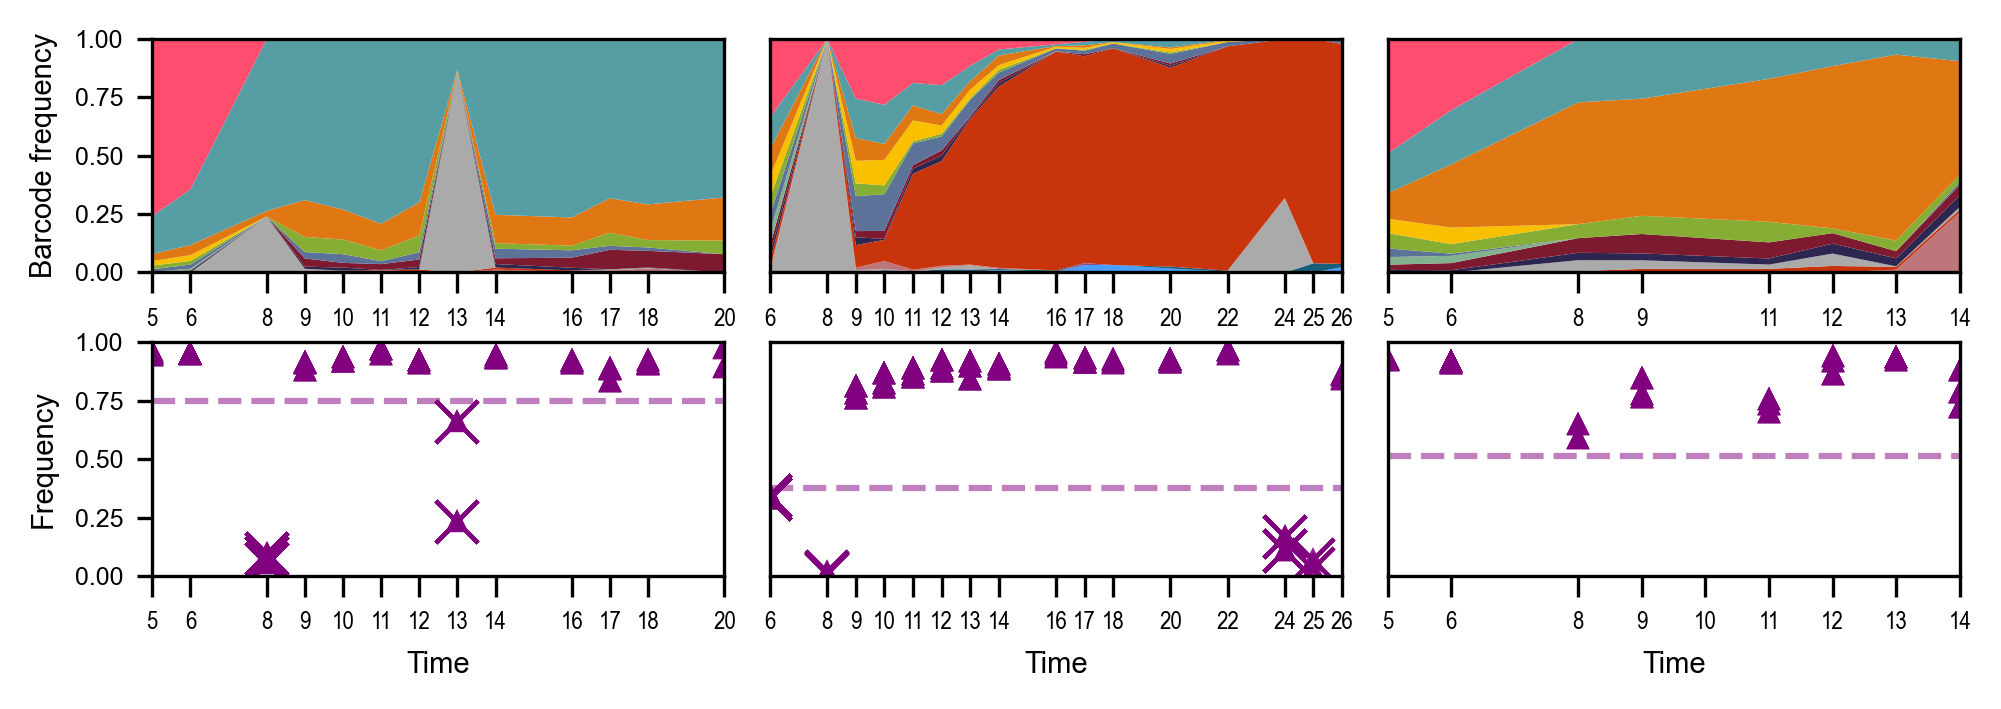

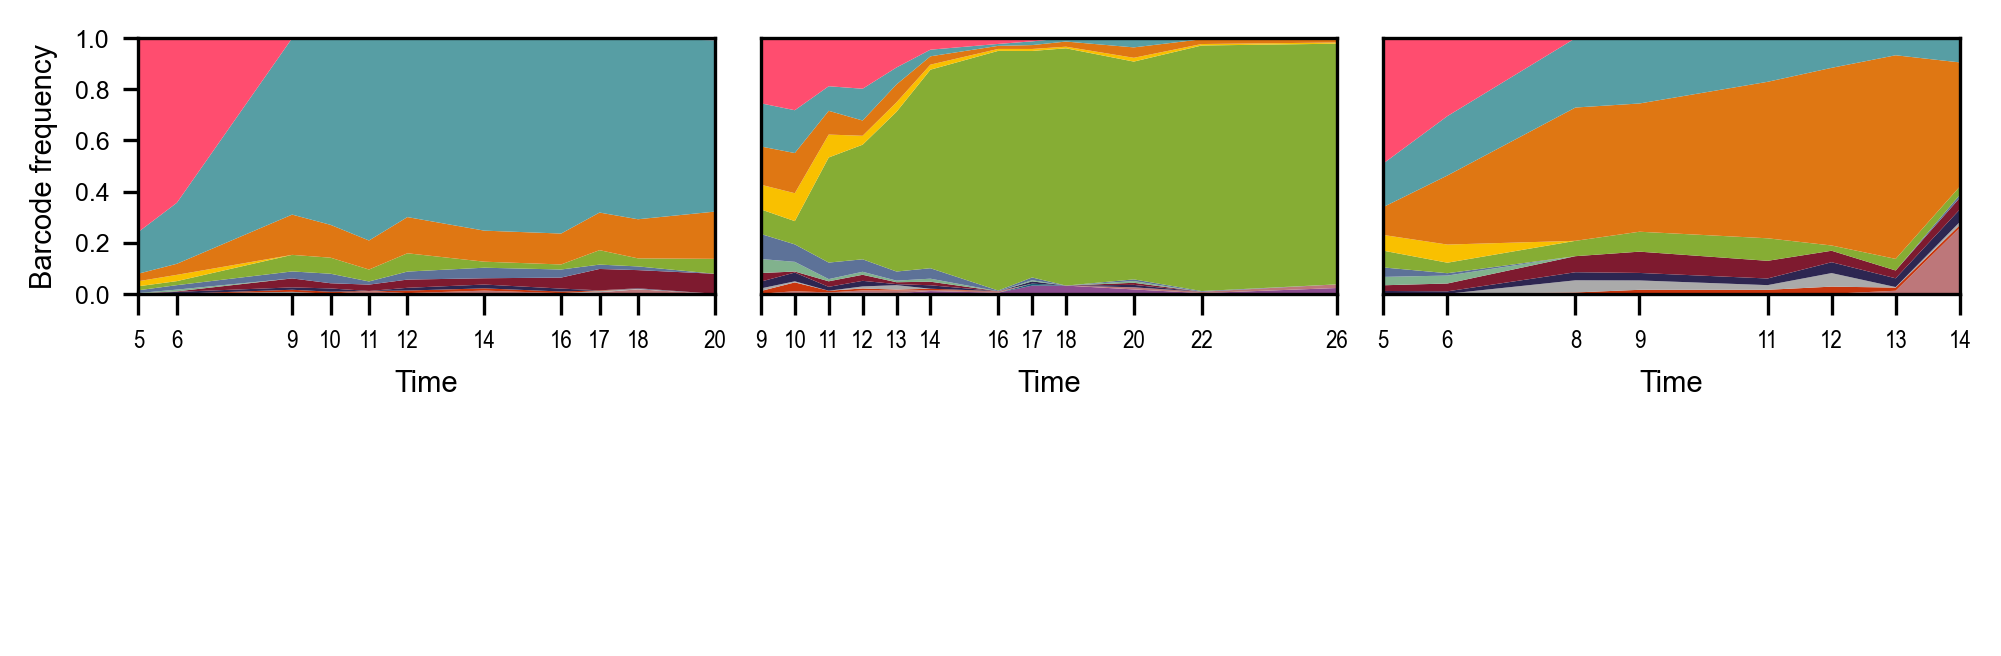

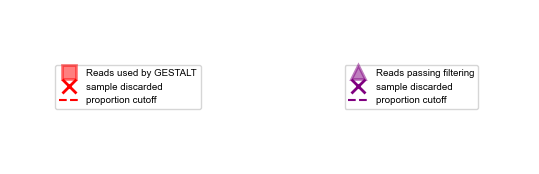

In [11]:
# Get the array of fishes we want to plot (cherry-picked for filter demonstration)
fishes_to_plot = ['fish1', 'fish12', 'fish15']
fishes = fishes_to_plot

#fishes = data1['fish'].unique()

# Create custom legends
legend1_elements = [
    # Red square for "used entry prop"
    plt.Line2D([0], [0], marker='s', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='Reads used by GESTALT'),
    plt.Line2D([0], [0], marker='x', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', 
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='red', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='--',
               label='proportion cutoff'),

]
legend2_elements = [
    # Purple triangle for "kept entry prop"
    plt.Line2D([0], [0], marker='^', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='Reads passing filtering'),
    plt.Line2D([0], [0], marker='x', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None',
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='--',
               label='proportion cutoff'),

]

# Section A
fig_width = 6.7
fig_height = 2.5

fig, ax = plt.subplots(2, len(fishes), figsize=(fig_width, fig_height), dpi=300)

for i, fish in enumerate(fishes):
    ad.plot_fish(fish, ax[0, i], data1)
    ad.show_anomalies(fish, ax[1, i], data1, metrics1, show_filtered=False, map_samples=True)
    ax[0, i].set_title(f'Fish {fish[4:]}', fontweight='bold')
    ax[0, i].tick_params(axis='x', labelsize=6, length=5)
    ax[1, i].tick_params(axis='x', labelsize=6, length=5)
    if i > 0: 
        ax[0, i].set_ylabel('')
        ax[0, i].set_yticks([])
        ax[1, i].set_yticks([])
    else:
        ax[1, i].set_ylabel('Frequency')
    for label in ax[0, i].get_xticklabels() + ax[1, i].get_xticklabels():
        label.set_fontname('Arial Narrow')
    fig.subplots_adjust(wspace=0.08, hspace=0.3)
plt.savefig(f'images/anomalies-no-filters.svg', format='svg')
plt.show()

# Section B
fig, ax = plt.subplots(2, len(fishes), figsize=(fig_width, fig_height), dpi=300)

for i, fish in enumerate(fishes):
    ad.plot_fish(fish, ax[0, i], data2)
    ad.show_anomalies(fish, ax[1, i], data2, metrics2, show_used=False, map_samples=True)
    ax[0, i].set_title(None)
    ax[0, i].tick_params(axis='x', labelsize=6, length=5)
    ax[1, i].tick_params(axis='x', labelsize=6, length=5)
    if i > 0: 
        ax[0, i].set_ylabel('')
        ax[0, i].set_yticks([])
        ax[1, i].set_yticks([])
    else:
        ax[1, i].set_ylabel('Frequency')
    for label in ax[0, i].get_xticklabels() + ax[1, i].get_xticklabels():
        label.set_fontname('Arial Narrow')
    fig.subplots_adjust(wspace=0.08, hspace=0.3)

plt.savefig(f'images/anomalies-first-filter.svg', format='svg')
plt.show()

# Section B
fig, ax = plt.subplots(2, len(fishes), figsize=(fig_width, fig_height), dpi=300)

# Section C
for i, fish in enumerate(fishes):
    ad.plot_fish(fish, ax[0, i], data3)
    ax[0, i].set_title(None)
    ax[0, i].tick_params(axis='x', labelsize=6, length=5)
    if i > 0: 
        ax[0, i].set_ylabel('')
        ax[0, i].set_yticks([])
    ax[1, i].set_axis_off()
    fig.subplots_adjust(wspace=0.08, hspace=0.3)
    for label in ax[0, i].get_xticklabels() + ax[1, i].get_xticklabels():
        label.set_fontname('Arial Narrow')
plt.savefig(f'images/anomalies-all-filters.svg', format='svg')
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(6.7, 2))
ax[0].set_axis_off()
ax[1].set_axis_off()

legend = ax[0].legend(handles=legend1_elements, 
                   loc='center', 
                   ncol=1,  # Display in 1 columns
                   frameon=True)  # Keep frame

legend = ax[1].legend(handles=legend2_elements, 
                   loc='center', 
                   ncol=1,  # Display in 1 columns
                   frameon=True)  # Keep frame

plt.savefig(f'images/anomalies-legend_seperate.svg', format='svg')
plt.show();